# Notebook 03 — Comparación de clasificadores y balanceos

Aquí comparamos 12 clasificadores con las formas de balanceo que sí son compatibles con nuestros datos, usando las mismas diez particiones por grupos que dejó el notebook 02. Solo leemos entrenamiento: el conjunto de prueba sigue reservado para el notebook 04.

Seguimos la métrica principal acordada, el F1 de la clase de abandono, y reportamos precisión, recall, ROC AUC, precisión promedio y accuracy como complementos. El accuracy no decide nada. Todo lo que aprende de los datos (escalador y remuestreo) va dentro del pipeline, para que se ajuste solo con la parte de entrenamiento de cada partición.

Antes de comparar hay que resolver un punto que dejó pendiente el plan: cómo tratar las variables categóricas cuando sobremuestreamos.

In [1]:
EN_COLAB = False

if EN_COLAB:
    %pip install imbalanced-learn -q

    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_BASE = "/content/drive/MyDrive/Prediccion_Abandono_Clientes/"
else:
    RUTA_BASE = "./"

RUTA_DATOS = RUTA_BASE + "data/"
RUTA_MODELOS = RUTA_BASE + "models/"
RUTA_RESULTADOS = RUTA_BASE + "resultados/"
RUTA_FIGURAS = RUTA_BASE + "figuras/"

In [2]:
import os
import json
import time
import hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler

from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, precision_score, f1_score
from sklearn.neighbors import NearestNeighbors
from sklearn.tree import export_text

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, StackingClassifier)

for ruta in [RUTA_MODELOS, RUTA_RESULTADOS, RUTA_FIGURAS]:
    os.makedirs(ruta, exist_ok=True)

## Cargar entrenamiento, grupos y particiones del notebook 02

Leemos `train.csv`, los grupos de perfiles idénticos y la plantilla de preprocesamiento que guardó el notebook 02. Las diez particiones de validación no las volvemos a generar: las leemos de `02_particiones_cv.csv`, para comparar exactamente con las mismas filas. Verificamos que las entradas no hayan cambiado desde el 02 (huellas SHA256) y que ningún grupo quede a la vez en entrenamiento y validación.

In [3]:
train = pd.read_csv(RUTA_DATOS + "train.csv")
datos_grupos = pd.read_csv(RUTA_DATOS + "grupos_train.csv")
asignaciones_cv = pd.read_csv(RUTA_RESULTADOS + "02_particiones_cv.csv")
decisiones = joblib.load(RUTA_MODELOS + "decisiones_preprocesamiento.joblib")

with open(RUTA_DATOS + "particion_01.json", encoding="utf-8") as archivo:
    particion = json.load(archivo)

X_train = train.drop(columns="abandono")
y_train = train["abandono"]
grupos_train = datos_grupos["grupo"]

assert list(X_train.columns) == particion["columnas_entrada"] == decisiones["columnas_entrada"]
assert asignaciones_cv["fila_original"].tolist() == datos_grupos["fila_original"].tolist()
assert asignaciones_cv["grupo"].tolist() == grupos_train.tolist()
assert train.isna().sum().sum() == 0

# Las huellas confirman que son las mismas entradas con las que el notebook 02 tomó sus decisiones.
for nombre_archivo, huella in decisiones["sha256_entradas"].items():
    with open(RUTA_DATOS + nombre_archivo, "rb") as archivo:
        assert hashlib.sha256(archivo.read()).hexdigest() == huella

particiones_cv = []
for numero in range(1, 11):
    indices_validacion = np.where(asignaciones_cv["particion_validacion"] == numero)[0]
    indices_train = np.where(asignaciones_cv["particion_validacion"] != numero)[0]
    assert set(grupos_train.iloc[indices_train]).isdisjoint(set(grupos_train.iloc[indices_validacion]))
    particiones_cv.append((indices_train, indices_validacion))

plantilla = decisiones["preprocesamiento"]
print("Filas de entrenamiento:", len(train), "| entradas:", X_train.shape[1], "| abandonos:", int(y_train.sum()))
print("Particiones leídas:", len(particiones_cv))
print("Preprocesamiento elegido en el 02:", decisiones["alternativa"])
nombres_pasos = []
for nombre, paso in plantilla.steps:
    nombres_pasos.append(nombre)
print(nombres_pasos)

Filas de entrenamiento: 2511 | entradas: 11 | abandonos: 392
Particiones leídas: 10
Preprocesamiento elegido en el 02: StandardScaler
['escalador', 'transformador']


**Lo que notamos.** Trabajamos con 2.511 filas de entrenamiento, once entradas y 392 abandonos (15,61 %). Las diez particiones por grupos se leyeron tal como las dejó el notebook 02, las huellas de las entradas coinciden con las registradas allí y ningún grupo cruza entrenamiento y validación. El preprocesamiento heredado es `StandardScaler` sin PCA ni selección: la plantilla solo tiene el escalador y un paso que deja pasar los datos.

## Funciones de evaluación y de armado de pipelines

`evaluar_combinacion` evalúa un pipeline con las diez particiones por grupos y devuelve los promedios de las métricas, la desviación del F1 y el F1 de cada partición (para los box plots). Los modelos sin `predict_proba` (SVM y SVM lineal) igual entran en ROC AUC y precisión promedio, porque scikit-learn usa su puntaje de decisión.

`armar_pipeline` junta los pasos de la plantilla del notebook 02 con el balanceo y el clasificador. Como pidió el 02, concatenamos los pasos en un solo pipeline de imblearn y no anidamos un `Pipeline` dentro de otro.

In [4]:
metricas = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "precision_promedio": "average_precision"
}


def evaluar_combinacion(pipeline, X, y, particiones, metricas, nombre):
    """
    Evalúa un pipeline con las particiones por grupos que recibe y devuelve un diccionario con el promedio de
    cada métrica, la desviación del F1, el F1 de cada partición y el tiempo que tardó.
    No modifica el pipeline recibido: cross_validate trabaja con copias.
    """
    inicio = time.time()
    scores = cross_validate(
        pipeline, X, y,
        cv=particiones,
        scoring=metricas,
        n_jobs=-1,
        error_score="raise"
    )

    return {
        "Nombre": nombre,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "F1_std": scores["test_f1"].std(ddof=1),
        "ROC_AUC": scores["test_roc_auc"].mean(),
        "Precision_promedio": scores["test_precision_promedio"].mean(),
        "F1_por_particion": scores["test_f1"],
        "Tiempo_s": time.time() - inicio
    }


def posiciones_categoricas(columnas, nombres_categoricos):
    """
    Recibe las columnas de X y los nombres de las columnas categóricas.
    Devuelve la posición de cada una, que es lo que necesita SMOTENC para saber cuáles no interpolar.
    """
    posiciones = []
    for nombre in nombres_categoricos:
        posiciones.append(list(columnas).index(nombre))
    return posiciones


def crear_balanceador(estrategia, posiciones_cat):
    """
    Devuelve el paso de balanceo que corresponde a la estrategia, o None si no lleva remuestreo.
    SMOTENC necesita saber qué columnas son categóricas; SMOTE a secas las trata a todas como continuas.
    """
    if estrategia == "SMOTE":
        return SMOTE(random_state=42)
    elif estrategia == "SMOTENC":
        return SMOTENC(categorical_features=posiciones_cat, random_state=42)
    elif estrategia == "Submuestreo":
        return RandomUnderSampler(random_state=42)
    return None


def admite_class_weight(modelo):
    """
    Dice si el modelo tiene el parámetro class_weight. KNN, Naive Bayes, MLP, Bagging, AdaBoost,
    Gradient Boosting y Stacking no lo tienen, así que con ellos esa estrategia no aplica.
    """
    return "class_weight" in modelo.get_params()


def armar_pipeline(plantilla, modelo, estrategia, posiciones_cat):
    """
    Arma un pipeline plano de imblearn: pasos de la plantilla del notebook 02, balanceo (si la estrategia
    lo lleva) y clasificador. Con class_weight no hay remuestreo: se pide al modelo que pese las clases.
    Trabaja con copias, así una combinación no afecta a la siguiente.
    """
    pasos = list(clone(plantilla).steps)
    balanceador = crear_balanceador(estrategia, posiciones_cat)
    if balanceador is not None:
        pasos.append(("balanceo", balanceador))
    modelo = clone(modelo)
    if estrategia == "class_weight":
        modelo.set_params(class_weight="balanced")
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)

## Tratamiento de las categorías al sobremuestrear

`SMOTE` crea turnos nuevos interpolando entre vecinos, algo que tiene sentido para variables continuas como `segundos_uso`, pero no para `quejas` (0 o 1) ni `plan_tarifario` (1 o 2): una interpolación daría valores como 0,4 que no existen. `SMOTENC` está pensado para esto: en las columnas categóricas no interpola, sino que toma la categoría más frecuente entre los vecinos.

Tratamos como categóricas solo las dos columnas que son nominales de verdad: `quejas` y `plan_tarifario`. Dejamos como numéricas `nivel_cargo`, `grupo_edad` y `edad`, porque son ordinales y su orden sí es información. Para comprobarlo, aplicamos los dos sobremuestreos a la primera partición de entrenamiento (ya escalada) y contamos cuántos valores de esas dos columnas aparecen en los turnos sintéticos sin existir en los datos reales.

In [5]:
COLUMNAS_CATEGORICAS = ["quejas", "plan_tarifario"]
posiciones_cat = posiciones_categoricas(X_train.columns, COLUMNAS_CATEGORICAS)
print("Posiciones de las columnas categóricas:", posiciones_cat)


def contar_valores_inventados(X, y, indices_train, plantilla, balanceador, posiciones):
    """
    Escala una partición de entrenamiento con la plantilla, la sobremuestrea y cuenta, en cada columna de
    `posiciones`, cuántos valores de los turnos sintéticos no existían en los datos reales.
    Devuelve un diccionario con la cantidad de turnos sintéticos y el conteo por columna.
    """
    X_partido = X.iloc[indices_train]
    y_partido = y.iloc[indices_train]
    X_escalado = clone(plantilla).fit_transform(X_partido)
    X_nuevo, y_nuevo = balanceador.fit_resample(X_escalado, y_partido)
    # imblearn agrega los turnos sintéticos al final, después de los reales
    sinteticos = X_nuevo[len(X_escalado):]

    resultado = {"Turnos_sinteticos": len(sinteticos)}
    for posicion in posiciones:
        valores_reales = np.unique(np.round(X_escalado[:, posicion], 6))
        valores_nuevos = np.round(sinteticos[:, posicion], 6)
        resultado[X.columns[posicion]] = int((~np.isin(valores_nuevos, valores_reales)).sum())
    return resultado


rows_inventados = []
for nombre_estrategia in ["SMOTE", "SMOTENC"]:
    balanceador = crear_balanceador(nombre_estrategia, posiciones_cat)
    fila = contar_valores_inventados(
        X_train, y_train, particiones_cv[0][0], plantilla, balanceador, posiciones_cat
    )
    fila["Estrategia"] = nombre_estrategia
    rows_inventados.append(fila)

tabla_inventados = pd.DataFrame(rows_inventados)
tabla_inventados.to_csv(RUTA_RESULTADOS + "03_valores_inventados_sobremuestreo.csv", index=False)
tabla_inventados

Posiciones de las columnas categóricas: [1, 9]


,Turnos_sinteticos,quejas,plan_tarifario,Estrategia
0,1554,0,12,SMOTE
1,1554,0,0,SMOTENC


**Lo que notamos.** En la primera partición, `SMOTE` generó 1.554 turnos sintéticos y 12 de ellos tienen un valor de `plan_tarifario` que no existe en los datos reales (menos del 1 %); `SMOTENC` no inventó ninguno. En `quejas` ninguno de los dos inventó valores. Lo atribuimos a que, ya estandarizada, `quejas` separa tanto a los clientes (los que se quejan quedan muy lejos de los que no) que los vecinos de un cliente casi siempre comparten su valor. Es decir, en este conjunto el problema es pequeño, pero `SMOTENC` lo elimina por completo.

Ahora vemos si el cambio importa también en el F1. Comparamos `SMOTE` y `SMOTENC` con dos modelos distintos (una regresión logística y KNN, que depende de distancias) y las diez particiones. Esta comparación es solo un control: elegimos `SMOTENC` por la validez de sus turnos sintéticos, no por cuál dé un número más alto.

In [6]:
rows_control = []
for nombre_modelo, modelo in [
    ("Regresión logística", LogisticRegression(max_iter=2000, random_state=42)),
    ("KNN", KNeighborsClassifier(n_neighbors=5))
]:
    for nombre_estrategia in ["SMOTE", "SMOTENC"]:
        pipeline = armar_pipeline(plantilla, modelo, nombre_estrategia, posiciones_cat)
        fila = evaluar_combinacion(
            pipeline, X_train, y_train, particiones_cv, metricas,
            nombre_modelo + " | " + nombre_estrategia
        )
        fila["Modelo"] = nombre_modelo
        fila["Estrategia"] = nombre_estrategia
        rows_control.append(fila)
        print(nombre_modelo, "|", nombre_estrategia, "-> F1 =", round(fila["F1"], 3))

tabla_control = pd.DataFrame(rows_control)
columnas_control = ["Modelo", "Estrategia", "F1", "F1_std", "Precision", "Recall", "ROC_AUC", "Precision_promedio"]
tabla_control[columnas_control].to_csv(RUTA_RESULTADOS + "03_control_sobremuestreo.csv", index=False)
tabla_control[columnas_control].round(3)

Regresión logística | SMOTE -> F1 = 0.589


Regresión logística | SMOTENC -> F1 = 0.583
KNN | SMOTE -> F1 = 0.801


KNN | SMOTENC -> F1 = 0.793


,Modelo,Estrategia,F1,F1_std,Precision,Recall,ROC_AUC,Precision_promedio
0,Regresión logística,SMOTE,0.589,0.066,0.448,0.865,0.924,0.744
1,Regresión logística,SMOTENC,0.583,0.066,0.443,0.860,0.924,0.743
2,KNN,SMOTE,0.801,0.056,0.714,0.918,0.956,0.805
3,KNN,SMOTENC,0.793,0.061,0.714,0.898,0.954,0.797


**Lo que notamos.** El F1 casi no cambia: con regresión logística es 0,589 con `SMOTE` y 0,583 con `SMOTENC`, y con KNN 0,801 y 0,793. Las diferencias son menores que la desviación entre particiones (entre 0,056 y 0,066), así que no hay ventaja real de uno sobre otro. Como dijimos, la decisión no depende del F1: usamos `SMOTENC` en toda la comparación porque sus turnos sintéticos son siempre válidos.

También llama la atención que KNN ya llegue a 0,80 mientras la regresión logística se queda en 0,58 y 0,59 con los mismos datos. Lo revisamos más abajo.

## Catálogo de modelos

Los 12 modelos van en una función que devuelve una lista de parejas (nombre, modelo sin entrenar). Son 8 individuales y 4 ensambles. No les ponemos `n_jobs=-1` porque la validación cruzada ya corre en paralelo.

Una advertencia sobre Stacking: su validación cruzada interna (`cv=5`) no puede recibir los grupos, así que sus particiones internas pueden separar clientes de un mismo perfil repetido. Solo afecta al ajuste de su meta-modelo, no a la evaluación externa por grupos, pero lo dejamos anotado como limitación.

In [7]:
def crear_modelos():
    """
    Devuelve los 12 modelos que comparamos, como parejas (nombre, modelo sin entrenar).
    Si queremos probar otro, basta con agregar una línea aquí; el resto del notebook no cambia.
    """
    modelos = [
        ("KNN", KNeighborsClassifier(n_neighbors=5)),
        ("Naive Bayes", GaussianNB()),
        ("Árbol de decisión", DecisionTreeClassifier(random_state=42)),
        ("Regresión logística", LogisticRegression(max_iter=2000, random_state=42)),
        ("SVM", SVC(random_state=42)),
        ("SVM lineal", LinearSVC(max_iter=10000, random_state=42)),
        ("Red neuronal (MLP)", MLPClassifier(max_iter=1000, random_state=42)),
        ("Random Forest", RandomForestClassifier(n_estimators=200, random_state=42)),
        ("Bagging", BaggingClassifier(random_state=42)),
        ("AdaBoost", AdaBoostClassifier(random_state=42)),
        ("Gradient Boosting", GradientBoostingClassifier(random_state=42)),
        ("Stacking", StackingClassifier(
            estimators=[("rf", RandomForestClassifier(n_estimators=200, random_state=42)),
                        ("svm", SVC(random_state=42)),
                        ("knn", KNeighborsClassifier(n_neighbors=5))],
            final_estimator=LogisticRegression(max_iter=2000),
            cv=5)),
    ]
    return modelos


ESTRATEGIAS = ["Sin balanceo", "class_weight", "SMOTENC", "Submuestreo"]

n_combinaciones = 0
for nombre_modelo, modelo in crear_modelos():
    for estrategia in ESTRATEGIAS:
        if estrategia == "class_weight" and not admite_class_weight(modelo):
            continue
        n_combinaciones = n_combinaciones + 1
print("Combinaciones a evaluar:", n_combinaciones)

Combinaciones a evaluar: 41


**Lo que notamos.** Salen 41 combinaciones: 12 modelos por 3 estrategias son 36, más 5 combinaciones con `class_weight` (árbol, regresión logística, SVM, SVM lineal y Random Forest). Los otros siete modelos no tienen ese parámetro, así que esa casilla queda vacía a propósito.

## Comparación de las combinaciones

Recorremos los 12 modelos y las cuatro estrategias (sin balanceo, `class_weight`, `SMOTENC` y submuestreo) con dos ciclos y guardamos una fila por combinación en `rows`. La combinación `class_weight` se salta en los modelos que no la admiten; no es un olvido. Es posible que scikit-learn lance advertencias de convergencia o de precisión indefinida y no las ocultamos.

In [8]:
rows = []
for nombre_modelo, modelo in crear_modelos():
    for estrategia in ESTRATEGIAS:
        if estrategia == "class_weight" and not admite_class_weight(modelo):
            continue

        pipeline = armar_pipeline(plantilla, modelo, estrategia, posiciones_cat)
        fila = evaluar_combinacion(
            pipeline, X_train, y_train, particiones_cv, metricas,
            nombre_modelo + " | " + estrategia
        )
        fila["Modelo"] = nombre_modelo
        fila["Estrategia"] = estrategia
        rows.append(fila)
        print(nombre_modelo, "|", estrategia, "-> F1 =", round(fila["F1"], 3),
              "| tiempo:", round(fila["Tiempo_s"]), "s")

tabla_modelos = pd.DataFrame(rows).sort_values(
    "F1", ascending=False, kind="stable"
).reset_index(drop=True)
print("Combinaciones evaluadas:", len(tabla_modelos))

KNN | Sin balanceo -> F1 = 0.789 | tiempo: 0 s


KNN

 | SMOTENC -> F1 = 0.793 | tiempo: 0 s
KNN | Submuestreo -> F1 = 0.71 | tiempo: 0 s
Naive Bayes | Sin balanceo -> F1 = 0.518 | tiempo: 0 s


Naive Bayes | SMOTENC -> F1 = 0.459 | tiempo: 0 s
Naive Bayes | Submuestreo -> F1 = 0.478 | tiempo: 0 s
Árbol de decisión | Sin balanceo -> F1 = 0.794 | tiempo: 0 s
Árbol de decisión | class_weight -> F1 = 0.793 | tiempo: 0 s


Árbol de decisión | SMOTENC -> F1 = 0.761 | tiempo: 0 s
Árbol de decisión | Submuestreo -> F1 = 0.685 | tiempo: 0 s
Regresión logística | Sin balanceo -> F1 = 0.573 | tiempo: 0 s


...

Gradient Boosting | SMOTENC -> F1 = 0.775 | tiempo: 1 s


Gradient Boosting | Submuestreo -> F1 = 0.735 | tiempo: 0 s


Stacking | Sin balanceo -> F1 = 0.824 | tiempo: 6 s


Stacking | SMOTENC -> F1 = 0.862 | tiempo: 9 s


Stacking | Submuestreo -> F1 = 0.774 | tiempo: 4 s
Combinaciones evaluadas: 41


In [9]:
# La columna F1_por_particion (un arreglo por fila) no se guarda en el CSV; se usa aparte para los box plots.
columnas_tabla = ["Modelo", "Estrategia", "F1", "F1_std", "Recall", "Precision", "ROC_AUC",
                  "Precision_promedio", "Accuracy", "Tiempo_s"]
tabla_modelos[columnas_tabla].to_csv(RUTA_RESULTADOS + "comparacion_modelos.csv", index=False)
tabla_modelos[columnas_tabla].round(3)

,Modelo,Estrategia,F1,F1_std,Recall,Precision,ROC_AUC,Precision_promedio,Accuracy,Tiempo_s
0,Stacking,SMOTENC,0.862,0.051,0.895,0.834,0.981,0.897,0.955,9.328
1,Random Forest,class_weight,0.858,0.047,0.898,0.826,0.982,0.894,0.953,0.866
2,Random Forest,SMOTENC,0.854,0.046,0.888,0.827,0.980,0.886,0.953,1.283
3,Random Forest,Sin balanceo,0.839,0.054,0.801,0.884,0.984,0.918,0.952,0.833
4,Red neuronal (MLP),Sin balanceo,0.838,0.032,0.832,0.847,0.983,0.921,0.950,5.998
5,Red neuronal (MLP),SMOTENC,0.830,0.035,0.931,0.753,0.981,0.913,0.940,9.677
6,Stacking,Sin balanceo,0.824,0.065,0.788,0.869,0.983,0.922,0.948,5.511
7,Bagging,SMOTENC,0.819,0.045,0.831,0.810,0.966,0.858,0.943,0.289
8,Bagging,Sin balanceo,0.812,0.048,0.763,0.875,0.969,0.876,0.945,0.149
9,Red neuronal (MLP),Submuestreo,0.801,0.045,0.967,0.685,0.978,0.891,0.924,3.765


**Lo que notamos.** La comparación completa tardó poco más de un minuto. El mejor F1 es el de Stacking con `SMOTENC` (0,862 ± 0,051), seguido de Random Forest con `class_weight` (0,858) y con `SMOTENC` (0,854), Random Forest sin balancear (0,839) y la red neuronal sin balancear (0,838, con la desviación más baja de los primeros, 0,032). Al fondo quedan los modelos lineales y Naive Bayes: la regresión logística entre 0,573 y 0,596, la SVM lineal entre 0,564 y 0,584 y Naive Bayes entre 0,459 y 0,518.

El 0,596 de la regresión logística con `class_weight` coincide con el F1 de referencia que dio el notebook 02 (0,597), una buena señal de consistencia con el trabajo anterior. Lo que sorprende es el salto de 0,6 a 0,86 al pasar de modelos lineales a modelos basados en árboles. Antes de interpretarlo, lo revisamos.

## ¿Es creíble un F1 tan alto? Control de fuga entre particiones

La regresión logística de referencia del notebook 02 daba un F1 cercano a 0,6, y aquí los modelos de árboles, vecinos y ensambles llegan a más de 0,8. Un salto así puede ser una relación no lineal que los modelos lineales no alcanzan, pero también la huella de **filas casi idénticas** cruzando entrenamiento y validación, algo que agrupar solo por perfiles *exactamente* iguales no atrapa. Antes de interpretar nada lo comprobamos de dos maneras.

Primero, para cada fila buscamos su vecino más cercano entre las filas de las otras particiones (justo lo que vería un modelo en validación) y miramos si los vecinos muy cercanos comparten etiqueta más que los demás. Si hubiera casi-duplicados filtrando respuestas, los vecinos a distancia casi cero coincidirían mucho más en la etiqueta. Segundo, ajustamos un árbol muy corto con todo el entrenamiento solo para describir dónde está la señal.

In [10]:
def comparar_con_vecinos_de_otras_particiones(X_escalado, y, particiones):
    """
    Para cada fila busca su vecino más cercano entre las filas de las otras particiones, que es lo que un
    modelo vería en validación. Devuelve la distancia a ese vecino y si comparte etiqueta con la fila.
    """
    y_numpy = y.to_numpy()
    distancias = np.zeros(len(y))
    misma_etiqueta = np.zeros(len(y))
    for indices_train, indices_validacion in particiones:
        buscador = NearestNeighbors(n_neighbors=1).fit(X_escalado[indices_train])
        distancia, posicion = buscador.kneighbors(X_escalado[indices_validacion])
        distancias[indices_validacion] = distancia[:, 0]
        vecinos = y_numpy[indices_train][posicion[:, 0]]
        misma_etiqueta[indices_validacion] = (vecinos == y_numpy[indices_validacion])
    return distancias, misma_etiqueta


# Solo describimos: el escalador se ajusta con todo train porque aquí no estimamos rendimiento de nada.
X_escalado = clone(plantilla).fit_transform(X_train)
distancias, misma_etiqueta = comparar_con_vecinos_de_otras_particiones(X_escalado, y_train, particiones_cv)

rows_vecinos = []
for limite in [0.0, 0.05, 0.10, 0.25, 0.50, 100.0]:
    cercanas = distancias <= limite
    if cercanas.sum() > 0:
        coincidencia = misma_etiqueta[cercanas].mean()
    else:
        coincidencia = np.nan
    rows_vecinos.append({"Distancia_maxima": limite, "Filas": int(cercanas.sum()),
                         "Porcentaje_de_filas": cercanas.mean() * 100, "Coincidencia_de_etiqueta": coincidencia})

tabla_vecinos = pd.DataFrame(rows_vecinos)
tabla_vecinos.to_csv(RUTA_RESULTADOS + "03_control_fuga_vecinos.csv", index=False)
print(tabla_vecinos.round(3))

# Si el vecino más cercano de otra partición decidiera la etiqueta, este sería su F1.
prediccion_un_vecino = np.where(misma_etiqueta == 1, y_train, 1 - y_train)
print("\nF1 del vecino más cercano entre particiones:", round(f1_score(y_train, prediccion_un_vecino), 3))

arbol_corto = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42).fit(X_train, y_train)
print("\nÁrbol de profundidad 3 (solo descriptivo):")
print(export_text(arbol_corto, feature_names=list(X_train.columns)))

print("Abandono según quejas:")
print(train.groupby("quejas")["abandono"].agg(["mean", "sum", "count"]).round(3))

   Distancia_maxima  Filas  Porcentaje_de_filas  Coincidencia_de_etiqueta
0              0.00      0                0.000                       NaN
1              0.05     55                2.190                     0.818
2              0.10    117                4.659                     0.829
3              0.25    767               30.546                     0.896
4              0.50   2101               83.672                     0.931
5            100.00   2511              100.000                     0.935

F1 del vecino más cercano entre particiones: 0.786

Árbol de profundidad 3 (solo descriptivo):
|--- quejas <= 0.50
|   |--- frecuencia_uso <= 19.50
|   |   |--- grupo_edad <= 4.50
|   |   |   |--- class: 1
|   |   |--- grupo_edad >  4.50
|   |   |   |--- class: 0
|   |--- frecuencia_uso >  19.50
|   |   |--- frecuencia_sms <= 48.50
|   |   |   |--- class: 0
|   |   |--- frecuencia_sms >  48.50
|   |   |   |--- class: 0
|--- quejas >  0.50
|   |--- segundos_uso <= 6431.50
|   |

**Lo que notamos.** No hay ninguna fila con un vecino idéntico en otra partición (cero filas a distancia 0), así que la agrupación por perfiles sí está evitando los duplicados exactos. Los vecinos muy cercanos tampoco coinciden en etiqueta más que los demás: los 55 clientes con un vecino a distancia de 0,05 o menos (2,2 % de las filas) comparten etiqueta con él en el 81,8 % de los casos, y los 117 a distancia de 0,10 o menos en el 82,9 %, mientras que entre los 767 a distancia de 0,25 o menos (30,5 %) la coincidencia es 89,6 %. Si hubiera casi-duplicados filtrando la respuesta esperaríamos justo lo contrario, coincidencias cercanas al 100 % en los vecinos más pegados.

El vecino más cercano de otra partición, por sí solo, da un F1 de 0,786: los clientes de perfil parecido tienden a abandonar parecido, pero eso es estructura del problema y no fuga. El árbol de profundidad 3 muestra dónde está la señal. Entre quienes presentaron una queja (195 clientes) abandona el 83,1 % (162 clientes), y entre quienes no se quejaron solo el 9,9 % (230 de 2.316); dentro de los que no se quejaron, un uso bajo (`frecuencia_uso` hasta 19) marca el abandono. Son reglas con interacciones (queja y uso al mismo tiempo) que un modelo lineal no puede representar, y eso explica por qué la regresión logística se queda en 0,6 mientras los árboles llegan a 0,86.

Conclusión: no encontramos evidencia de fuga y el F1 alto parece real. Queda una cautela que no podemos resolver con estos datos: algunas entradas (por ejemplo tener uso cero) podrían reflejar que el cliente ya se había ido, y el conjunto no trae fechas para comprobarlo.

## Análisis

Primero el promedio de cada métrica por estrategia, para ver qué hace el balanceo en general. Después un mapa de calor del F1 con los modelos en las filas y las estrategias en las columnas (las combinaciones que no existen quedan vacías) y otro igual del recall.

In [11]:
promedios_estrategia = tabla_modelos.groupby("Estrategia")[
    ["F1", "Recall", "Precision", "ROC_AUC", "Precision_promedio", "Accuracy"]
].mean()
promedios_estrategia.round(3)

,F1,Recall,Precision,ROC_AUC,Precision_promedio,Accuracy
Estrategia,,,,,,
SMOTENC,0.727,0.885,0.642,0.947,0.804,0.882
Sin balanceo,0.708,0.675,0.825,0.948,0.823,0.912
Submuestreo,0.681,0.915,0.552,0.942,0.762,0.857
class_weight,0.708,0.881,0.613,0.938,0.784,0.876


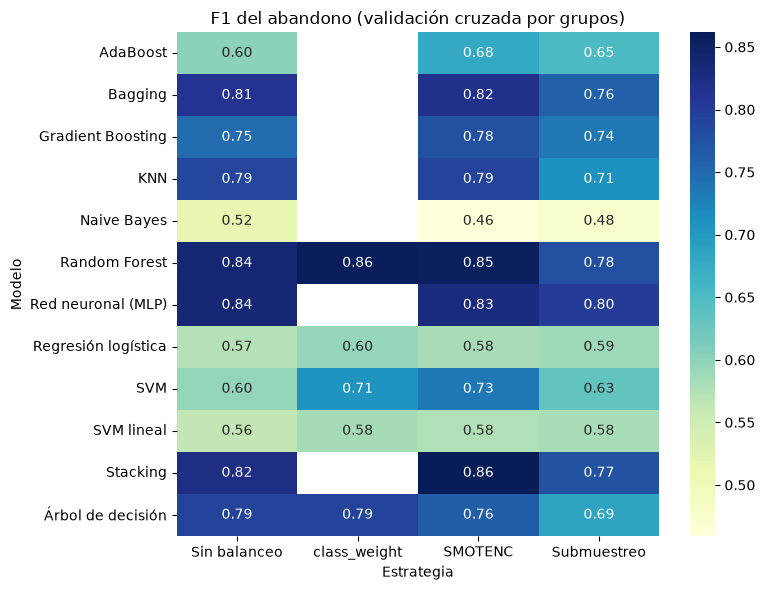

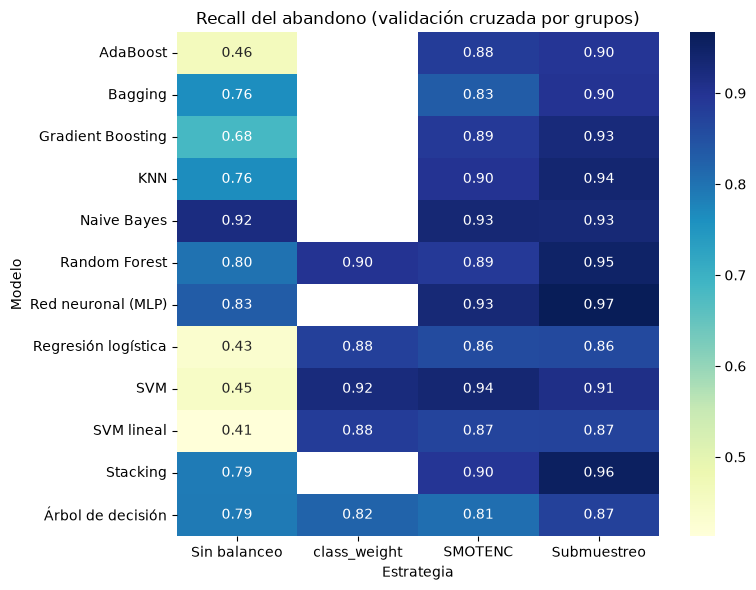

In [12]:
for metrica, nombre_archivo in [
    ("F1", "03_heatmap_f1_modelo_estrategia.png"),
    ("Recall", "03_heatmap_recall_modelo_estrategia.png")
]:
    matriz = tabla_modelos.pivot(index="Modelo", columns="Estrategia", values=metrica)
    matriz = matriz[ESTRATEGIAS]
    plt.figure(figsize=(8, 6))
    sns.heatmap(matriz, annot=True, fmt=".2f", cmap="YlGnBu")
    plt.title(metrica + " del abandono (validación cruzada por grupos)")
    plt.tight_layout()
    plt.savefig(RUTA_FIGURAS + nombre_archivo, bbox_inches="tight", dpi=150)
    plt.show()

**Lo que notamos.** A diferencia de lo que pasó en el problema de sismos, balancear cambia poco el F1 promedio: es 0,708 sin balancear, 0,727 con `SMOTENC`, 0,708 con `class_weight` (solo en 5 modelos) y 0,681 con submuestreo. Lo que sí cambia es el equilibrio entre recall y precisión. Sin balancear los modelos son precisos (0,825) pero dejan pasar abandonos (recall 0,675); con submuestreo detectan casi todos (recall 0,915) a costa de que solo el 55,2 % de sus alertas sea cierta; `SMOTENC` y `class_weight` quedan en un punto intermedio (recall 0,885 y 0,881, precisión 0,642 y 0,613). El ROC AUC promedio es parecido en todas las estrategias (entre 0,938 y 0,948): el orden que le dan los modelos a los clientes casi no depende del balanceo.

En el mapa de calor, los valores más altos se concentran en Random Forest, Stacking, la red neuronal y Bagging, sin importar la estrategia.

Para ver qué tan estables son los resultados, dibujamos el F1 de cada partición con la mejor estrategia de cada modelo.

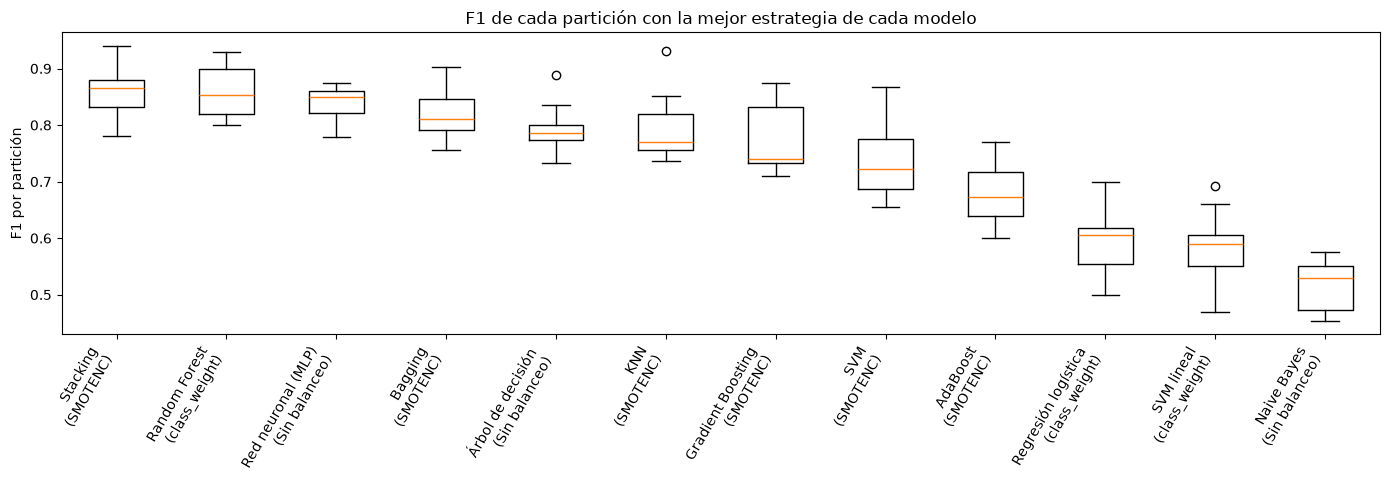

,Modelo,Estrategia,F1,F1_std,Recall,Precision,ROC_AUC,Precision_promedio
0,Stacking,SMOTENC,0.862,0.051,0.895,0.834,0.981,0.897
1,Random Forest,class_weight,0.858,0.047,0.898,0.826,0.982,0.894
4,Red neuronal (MLP),Sin balanceo,0.838,0.032,0.832,0.847,0.983,0.921
7,Bagging,SMOTENC,0.819,0.045,0.831,0.810,0.966,0.858
10,Árbol de decisión,Sin balanceo,0.794,0.043,0.790,0.804,0.901,0.707
11,KNN,SMOTENC,0.793,0.061,0.898,0.714,0.954,0.797
15,Gradient Boosting,SMOTENC,0.775,0.063,0.888,0.694,0.969,0.867
21,SVM,SMOTENC,0.735,0.066,0.937,0.607,0.969,0.847
25,AdaBoost,SMOTENC,0.679,0.059,0.883,0.557,0.947,0.795
30,Regresión logística,class_weight,0.596,0.065,0.878,0.454,0.925,0.745


In [13]:
# La tabla ya está ordenada por F1, así que la primera fila de cada modelo es su mejor estrategia.
mejores_por_modelo = tabla_modelos.drop_duplicates(subset="Modelo")

f1_por_modelo = []
etiquetas = []
for i in range(len(mejores_por_modelo)):
    fila = mejores_por_modelo.iloc[i]
    f1_por_modelo.append(fila["F1_por_particion"])
    etiquetas.append(fila["Modelo"] + "\n(" + fila["Estrategia"] + ")")

plt.figure(figsize=(14, 5))
plt.boxplot(f1_por_modelo)
plt.xticks(range(1, len(etiquetas) + 1), etiquetas, rotation=60, ha="right")
plt.ylabel("F1 por partición")
plt.title("F1 de cada partición con la mejor estrategia de cada modelo")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "03_boxplot_f1_por_particion.png", bbox_inches="tight", dpi=150)
plt.show()

mejores_por_modelo[["Modelo", "Estrategia", "F1", "F1_std", "Recall", "Precision", "ROC_AUC", "Precision_promedio"]].round(3)

**Lo que notamos.** La desviación del F1 entre particiones va de 0,032 a 0,066 según el modelo. Entre Stacking (0,862) y Random Forest (0,858) hay 0,004, un empate práctico, y la red neuronal sin balancear (0,838) queda a menos de media desviación del primero. Por debajo hay una brecha más clara: Bagging con 0,819 y el árbol con 0,794. Los tres primeros no se distinguen entre sí con estos datos.

Por último, accuracy contra F1. Cada punto es una combinación y la línea marca el accuracy de un modelo que siempre responde "permanece". Si el accuracy sirviera para decidir, las combinaciones con más accuracy tendrían también más F1.

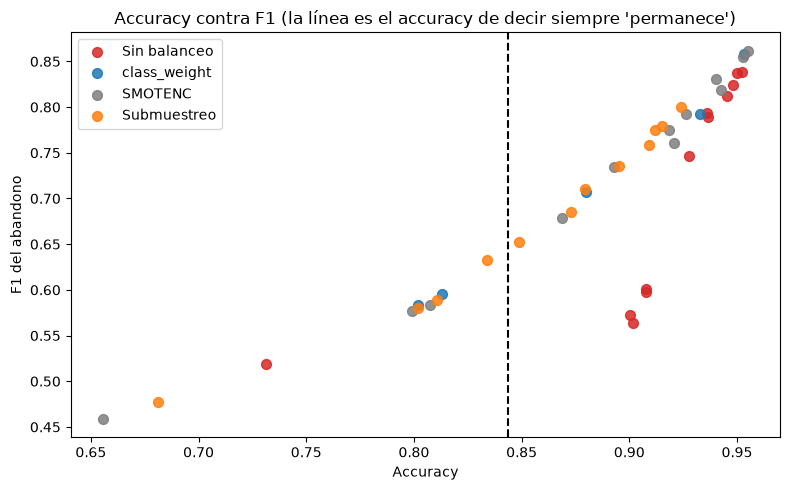

Accuracy de decir siempre 'permanece': 0.8439


In [14]:
colores = {"Sin balanceo": "tab:red", "class_weight": "tab:blue", "SMOTENC": "tab:gray", "Submuestreo": "tab:orange"}

plt.figure(figsize=(8, 5))
for estrategia in ESTRATEGIAS:
    parte = tabla_modelos[tabla_modelos["Estrategia"] == estrategia]
    plt.scatter(parte["Accuracy"], parte["F1"], label=estrategia, s=50, alpha=0.85, color=colores[estrategia])

accuracy_siempre_cero = 1 - y_train.mean()
plt.axvline(accuracy_siempre_cero, linestyle="--", color="black")
plt.xlabel("Accuracy")
plt.ylabel("F1 del abandono")
plt.title("Accuracy contra F1 (la línea es el accuracy de decir siempre 'permanece')")
plt.legend()
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "03_accuracy_vs_f1.png", bbox_inches="tight", dpi=150)
plt.show()
print("Accuracy de decir siempre 'permanece':", round(accuracy_siempre_cero, 4))

**Lo que notamos.** Aquí no hay una trampa del accuracy tan marcada como en el problema de sismos: el modelo que siempre responde "permanece" saca 0,8439 y 31 de las 41 combinaciones lo superan; además el accuracy y el F1 van de la mano (correlación de 0,875) porque el abandono es menos raro (15,6 %). Aun así el accuracy no sirve para decidir por sí solo: la SVM lineal sin balancear es la más precisa de las lineales (0,909) pero detecta apenas el 41,3 % de los abandonos (F1 de 0,564). Seguimos eligiendo por F1.

## Los tres candidatos

Los tres mejores pasan al notebook 04. Tomamos las tres primeras filas de la tabla pero de **modelos distintos**, porque si un mismo modelo apareciera con dos estrategias solo contamos la mejor. Seleccionamos con datos de entrenamiento únicamente. Además de las métricas mostramos cuánto se aleja cada candidato del mejor en unidades de la desviación del F1, para no leer como ventaja una diferencia que cabe en el ruido de la validación.

In [15]:
candidatos = tabla_modelos.drop_duplicates(subset="Modelo").head(3).reset_index(drop=True)

mejor_f1 = candidatos.loc[0, "F1"]
mejor_std = candidatos.loc[0, "F1_std"]
distancias = []
for i in range(len(candidatos)):
    distancias.append((mejor_f1 - candidatos.loc[i, "F1"]) / mejor_std)
candidatos["Distancia_al_mejor_en_desviaciones"] = distancias

columnas_candidatos = ["Modelo", "Estrategia", "F1", "F1_std", "Recall", "Precision", "ROC_AUC",
                       "Precision_promedio", "Accuracy", "Distancia_al_mejor_en_desviaciones"]
candidatos[columnas_candidatos].to_csv(RUTA_RESULTADOS + "03_candidatos.csv", index=False)
candidatos[columnas_candidatos].round(3)

,Modelo,Estrategia,F1,F1_std,Recall,Precision,ROC_AUC,Precision_promedio,Accuracy,Distancia_al_mejor_en_desviaciones
0,Stacking,SMOTENC,0.862,0.051,0.895,0.834,0.981,0.897,0.955,0.000
1,Random Forest,class_weight,0.858,0.047,0.898,0.826,0.982,0.894,0.953,0.069
2,Red neuronal (MLP),Sin balanceo,0.838,0.032,0.832,0.847,0.983,0.921,0.950,0.468


## Conclusiones

- **Candidatos.** Pasan al notebook 04 tres modelos de familias distintas: Stacking con `SMOTENC` (F1 0,862 ± 0,051), Random Forest con `class_weight` (0,858 ± 0,047) y la red neuronal sin balancear (0,838 ± 0,032). Están a 0, 0,07 y 0,47 desviaciones del mejor, o sea que los dos primeros son un empate práctico.
- **Qué significan estos números.** Son F1 de validación cruzada con el umbral por defecto de cada modelo; todavía no son el resultado final. El notebook 04 ajusta los hiperparámetros, calibra, escoge el umbral con entrenamiento y estima el rendimiento con validación anidada antes de abrir la prueba.
- **Lo lineal queda atrás.** La regresión logística, la SVM lineal y Naive Bayes se quedan entre 0,46 y 0,60, y la regresión logística reproduce el 0,6 que dio la comparación del notebook 02. Los modelos basados en árboles, la red neuronal y KNN llegan a entre 0,79 y 0,86 porque capturan interacciones, sobre todo entre quejas y uso.
- **El balanceo importa menos que en sismos.** El F1 promedio casi no cambia; el balanceo mueve el equilibrio entre recall y precisión, así que la elección real dependerá del costo de contactar a un cliente que no se iba a ir frente al de perder uno que sí.
- **Tratamiento de categorías.** `SMOTENC` con `quejas` y `plan_tarifario` como categóricas: `SMOTE` inventaba 12 valores inválidos de `plan_tarifario` en la primera partición y `SMOTENC` ninguno, sin diferencia relevante en el F1.
- **Control de fuga.** No hay duplicados exactos entre particiones ni señal de que los casi-duplicados regalen aciertos. Cautela abierta: no hay fechas, así que no podemos descartar que alguna entrada (como el uso cero) refleje un abandono ya ocurrido.
- **Limitación conocida.** La validación cruzada interna de Stacking (`cv=5`) no usa los grupos, y puede separar clientes de un mismo perfil repetido al ajustar su meta-modelo.
- **Archivos generados.** `resultados/comparacion_modelos.csv`, `resultados/03_candidatos.csv`, `resultados/03_control_sobremuestreo.csv`, `resultados/03_valores_inventados_sobremuestreo.csv`, `resultados/03_control_fuga_vecinos.csv` y las figuras `03_*.png`.

**Siguiente paso:** el notebook 04.